# RQ4 — Classification of ASD vs. Control from Harmonised Cortical Thickness
### SVM · CART · KNN · Naïve Bayes · Soft-Voting Ensemble

**Research question (RQ4):** *Can the ComBat-harmonised Desikan–Killiany cortical-thickness
features distinguish ASD from typically-developing controls, and which classifier family
performs best under a leakage-free evaluation protocol?*

This notebook is a corrected, from-scratch rewrite of the earlier RQ4 notebook. The
methodology below states exactly what was fixed and why, so the analysis is reproducible
and defensible.

---
## Methodology & corrections

The input file `abide_harmonised_combat.csv` is **already ComBat-harmonised**, so this
notebook treats it as the analysis-ready matrix. The following problems in the previous
version have been corrected:

1. **Redundant / leaky re-harmonisation removed.** The old notebook re-ran `neuroCombat`
   on the *entire* cohort (train + test together) before splitting. That both (a) duplicated
   harmonisation that was already done upstream and (b) leaked test-set information into
   training. ComBat is no longer run here.
2. **Undefined-variable crash fixed.** The old harmonisation cell used `THICKNESS_COLS`
   *before* it was defined, and read `abide_merged.csv` (a different file). Removed.
3. **Label encoding made consistent.** Labels are recoded to a clean binary
   **ASD = 1 (positive), Control = 0**. The old `{1: ASD, 2: Control}` coding combined with
   `confusion_matrix(...).ravel()` silently **swapped sensitivity and specificity** in the
   test block. That is fixed — sensitivity is now ASD recall, specificity is Control recall.
4. **Probability column fixed.** With the clean coding, `predict_proba[:, 1]` is `P(ASD)`
   everywhere, so CV-AUC and test-AUC measure the same thing.
5. **Contradictory pipeline definitions resolved.** The old notebook redefined
   `FEATURE_SETS` and `make_pipe` twice — the second definition forced everything through
   `PCA(20)` and discarded both the RQ1-confirmed F8 set and the interpretable CART tree.
   We keep two coherent, interpretable feature sets (**F8** and **F68**) with a single
   leakage-safe pipeline (`StandardScaler → classifier`). PCA is unnecessary for 68 features
   and would break the F8 interpretation, so it is not forced.
6. **Leakage protocol made explicit.** All sample-statistics-based steps (scaling) live
   *inside* the `Pipeline`, so they are refit on each CV fold's training portion only. The
   test set is sealed until the final block.

**Caveat (stated honestly):** because harmonisation was performed upstream over the whole
cohort, a small amount of harmonisation-stage information is shared across the eventual
split. This is a known, widely-accepted limitation of cohort-level ComBat and is independent
of this notebook; the downstream modelling here is leakage-free.

### Imports & configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Classifiers
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import VotingClassifier

# Metrics
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_curve, auc
)

# ── Configuration ───────────────────────────────────────────
DATA_PATH    = 'abide_harmonised_combat.csv'   # already ComBat-harmonised
RANDOM_STATE = 42
N_SPLITS     = 5        # stratified k-fold for cross-validation
TEST_SIZE    = 0.20     # held-out test fraction

# ASD is the POSITIVE class throughout: ASD = 1, Control = 0
POS_LABEL    = 1
CLASS_NAMES  = ['Control', 'ASD']   # index 0 -> Control, index 1 -> ASD
PALETTE      = {'ASD': '#E05C2A', 'Control': '#2A7AE0'}

sns.set_style('whitegrid')
print('All imports successful.')

All imports successful.


---
## Block 1 — Load harmonised data & build a clean binary target

We auto-detect the standard ABIDE columns so the notebook is robust to minor naming
differences, recode the target to **ASD = 1 / Control = 0**, and drop subjects with any
missing thickness value.

In [2]:
df = pd.read_csv(DATA_PATH)
df.replace(-9999, np.nan, inplace=True)

# ── Robustly locate the key metadata columns ─────────────────
def find_col(candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

DX_COL   = find_col(['DX_GROUP', 'DX', 'dx_group', 'diagnosis'])
SITE_COL = find_col(['SITE_ID', 'SITE', 'site'])
SEX_COL  = find_col(['SEX', 'sex', 'SEX_LABEL', 'Sex'])
AGE_COL  = find_col(['AGE_AT_SCAN', 'AGE', 'age'])

assert DX_COL is not None, 'Could not find a diagnosis column (DX_GROUP).'

# 68 Desikan-Killiany cortical-thickness columns
THICKNESS_COLS = [c for c in df.columns if c.startswith(('lh_', 'rh_'))]
assert len(THICKNESS_COLS) > 0, 'No lh_/rh_ thickness columns found.'

print(f'Detected columns -> DX:{DX_COL}  SITE:{SITE_COL}  SEX:{SEX_COL}  AGE:{AGE_COL}')
print(f'Thickness regions: {len(THICKNESS_COLS)}')

# ── Clean binary target: ABIDE DX_GROUP is 1=Autism, 2=Control ───────────────
# Recode to ASD=1 (positive), Control=0 regardless of original 1/2 or string coding.
dx_raw = df[DX_COL]
if dx_raw.dtype == object:
    df['y'] = dx_raw.astype(str).str.upper().str.startswith('A').astype(int)  # 'ASD'/'Autism'
else:
    df['y'] = (dx_raw == 1).astype(int)   # ABIDE: 1 = Autism/ASD

# ── Drop subjects with any missing thickness ─────────────────
n0 = len(df)
df = df.dropna(subset=THICKNESS_COLS).reset_index(drop=True)
print(f'\nSubjects: {n0} -> {len(df)} after dropping missing thickness')
print(f'  ASD (y=1)     : {(df.y==1).sum()}')
print(f'  Control (y=0) : {(df.y==0).sum()}')
if SITE_COL: print(f'  Sites         : {df[SITE_COL].nunique()}')

Detected columns -> DX:DX_GROUP  SITE:SITE_ID  SEX:SEX  AGE:AGE_AT_SCAN
Thickness regions: 68

Subjects: 1027 -> 1027 after dropping missing thickness
  ASD (y=1)     : 499
  Control (y=0) : 528
  Sites         : 20


---
## Block 2 — Strict, stratified train / test split

We stratify by **diagnosis × site × sex** so that scanner sites and sex are balanced across
the split (important for ABIDE). Strata with a single member are dropped because they cannot
be stratified. The test set is then **sealed** and not touched again until Block 9.

In [3]:
# Build a stratification key from whatever metadata is available
parts = [df['y'].astype(str)]
if SITE_COL: parts.append(df[SITE_COL].astype(str))
if SEX_COL:  parts.append(df[SEX_COL].astype(str))
strat_key = parts[0]
for p in parts[1:]:
    strat_key = strat_key + '_' + p

# Remove singleton strata (cannot appear in both train and test)
vc = strat_key.value_counts()
keep = strat_key.isin(vc[vc >= 2].index)
df = df[keep].reset_index(drop=True)
strat_key = strat_key[keep].reset_index(drop=True)
print(f'After removing singleton strata: {len(df)} subjects')

idx_all = np.arange(len(df))
idx_tr, idx_te = train_test_split(
    idx_all, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=strat_key
)
df_train = df.iloc[idx_tr].reset_index(drop=True)
df_test  = df.iloc[idx_te].reset_index(drop=True)

print(f'\nTrain: {len(df_train)}  (ASD={int(df_train.y.sum())}, '
      f'Control={int((df_train.y==0).sum())})')
print(f'Test : {len(df_test)}  (ASD={int(df_test.y.sum())}, '
      f'Control={int((df_test.y==0).sum())})')
print('\n🔒 df_test is sealed — not accessed again until Block 9.')

After removing singleton strata: 1023 subjects

Train: 818  (ASD=397, Control=421)
Test : 205  (ASD=100, Control=105)

🔒 df_test is sealed — not accessed again until Block 9.


---
## Block 3 — Feature sets

- **F8** — the 8 regions confirmed significant in RQ1 (FDR-corrected on harmonised data).
  Interpretable, low-dimensional.
- **F68** — all 68 Desikan–Killiany cortical-thickness regions.

We compare both so we can see whether the focused RQ1 signal classifies as well as the full
feature space.

In [4]:
CONFIRMED_8 = [
    'lh_lateraloccipital', 'rh_lateraloccipital',
    'lh_lingual',          'rh_lingual',
    'lh_cuneus',           'lh_entorhinal',
    'lh_medialorbitofrontal', 'lh_pericalcarine',
]
CONFIRMED_8 = [c for c in CONFIRMED_8 if c in THICKNESS_COLS]
print(f'F8 regions present in data: {len(CONFIRMED_8)} / 8')
if len(CONFIRMED_8) < 8:
    print('  (Missing F8 names will simply be skipped.)')

FEATURE_SETS = {
    'F8_confirmed': CONFIRMED_8,
    'F68_all'     : THICKNESS_COLS,
}

y_train = df_train['y'].values   # ASD=1, Control=0
y_test  = df_test['y'].values

X_train_sets = {n: df_train[c].values for n, c in FEATURE_SETS.items()}
X_test_sets  = {n: df_test[c].values  for n, c in FEATURE_SETS.items()}

print('\nFeature-set shapes (train):')
for n, X in X_train_sets.items():
    print(f'  {n:14s}: {X.shape}')

F8 regions present in data: 8 / 8

Feature-set shapes (train):
  F8_confirmed  : (818, 8)
  F68_all       : (818, 68)


---
## Block 4 — Leakage-safe pipeline & cross-validation setup

`StandardScaler` lives **inside** the pipeline, so under `GridSearchCV` / `cross_validate`
it is refit on each fold's *training* portion only — no validation/test statistics leak in.
Hyper-parameters are tuned on the **training set only**.

In [5]:
def make_pipe(estimator):
    """StandardScaler -> estimator. Scaler refit per CV fold (no leakage)."""
    return Pipeline([('scaler', StandardScaler()), ('clf', estimator)])

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

# With ASD=1 as the positive class, 'f1' and 'recall' use pos_label=1 by default.
SCORING = {
    'accuracy'         : 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'roc_auc'          : 'roc_auc',
    'f1'               : 'f1',        # F1 for ASD
    'sensitivity'      : 'recall',    # recall of ASD = sensitivity
}

def summarise_cv(name, cv_res):
    row = {'Model': name}
    for m in ['roc_auc', 'accuracy', 'balanced_accuracy', 'f1', 'sensitivity']:
        s = cv_res[f'test_{m}']
        row[f'{m}_mean'] = s.mean()
        row[f'{m}_std']  = s.std()
    return row

print(f'CV: {N_SPLITS}-fold stratified, train set only. Positive class = ASD (1).')

CV: 5-fold stratified, train set only. Positive class = ASD (1).


---
## Block 5 — Support Vector Machine (linear & RBF)

`C` (and `gamma` for RBF) tuned by `GridSearchCV` on the training set. `class_weight='balanced'`
handles the mild ASD/Control imbalance. `probability=True` enables ROC and soft voting.

In [6]:
cv_results_svm, best_pipes_svm = {}, {}
grid_lin = {'clf__C': [0.001, 0.01, 0.1, 1, 10, 100]}
grid_rbf = {'clf__C': [0.01, 0.1, 1, 10, 100], 'clf__gamma': ['scale', 'auto', 0.001, 0.01]}

for feat, X_tr in X_train_sets.items():
    print(f'=== SVM — {feat} ({X_tr.shape[1]} features) ===')
    for kernel, grid in [('linear', grid_lin), ('rbf', grid_rbf)]:
        key = f'SVM_{kernel}_{feat}'
        pipe = make_pipe(SVC(kernel=kernel, probability=True,
                             class_weight='balanced', random_state=RANDOM_STATE))
        gs = GridSearchCV(pipe, grid, cv=cv, scoring='roc_auc', n_jobs=-1, refit=True)
        gs.fit(X_tr, y_train)
        cv_res = cross_validate(gs.best_estimator_, X_tr, y_train, cv=cv, scoring=SCORING)
        cv_results_svm[key] = cv_res
        best_pipes_svm[key] = gs.best_estimator_
        print(f'  {kernel:6s} best={gs.best_params_}')
        print(f'         AUC {cv_res["test_roc_auc"].mean():.3f}±{cv_res["test_roc_auc"].std():.3f} | '
              f'Acc {cv_res["test_accuracy"].mean():.3f} | '
              f'Sens {cv_res["test_sensitivity"].mean():.3f}')
    print()
print('✅ SVM block complete.')

=== SVM — F8_confirmed (8 features) ===
  linear best={'clf__C': 0.001}
         AUC 0.565±0.045 | Acc 0.557 | Sens 0.334
  rbf    best={'clf__C': 1, 'clf__gamma': 0.001}
         AUC 0.565±0.045 | Acc 0.534 | Sens 0.368

=== SVM — F68_all (68 features) ===
  linear best={'clf__C': 0.01}
         AUC 0.601±0.024 | Acc 0.582 | Sens 0.511
  rbf    best={'clf__C': 100, 'clf__gamma': 0.001}
         AUC 0.596±0.017 | Acc 0.566 | Sens 0.539

✅ SVM block complete.


---
## Block 6 — CART (Decision Tree)

A binary tree, tuned over depth / leaf size / split criterion. We visualise the best F8 tree
because it is directly interpretable in terms of brain regions.

CART — F8_confirmed: best={'clf__criterion': 'entropy', 'clf__max_depth': 6, 'clf__min_samples_leaf': 10}
        AUC 0.579±0.036 | Acc 0.559 | Sens 0.427

CART — F68_all: best={'clf__criterion': 'gini', 'clf__max_depth': 5, 'clf__min_samples_leaf': 10}
        AUC 0.544±0.052 | Acc 0.518 | Sens 0.456



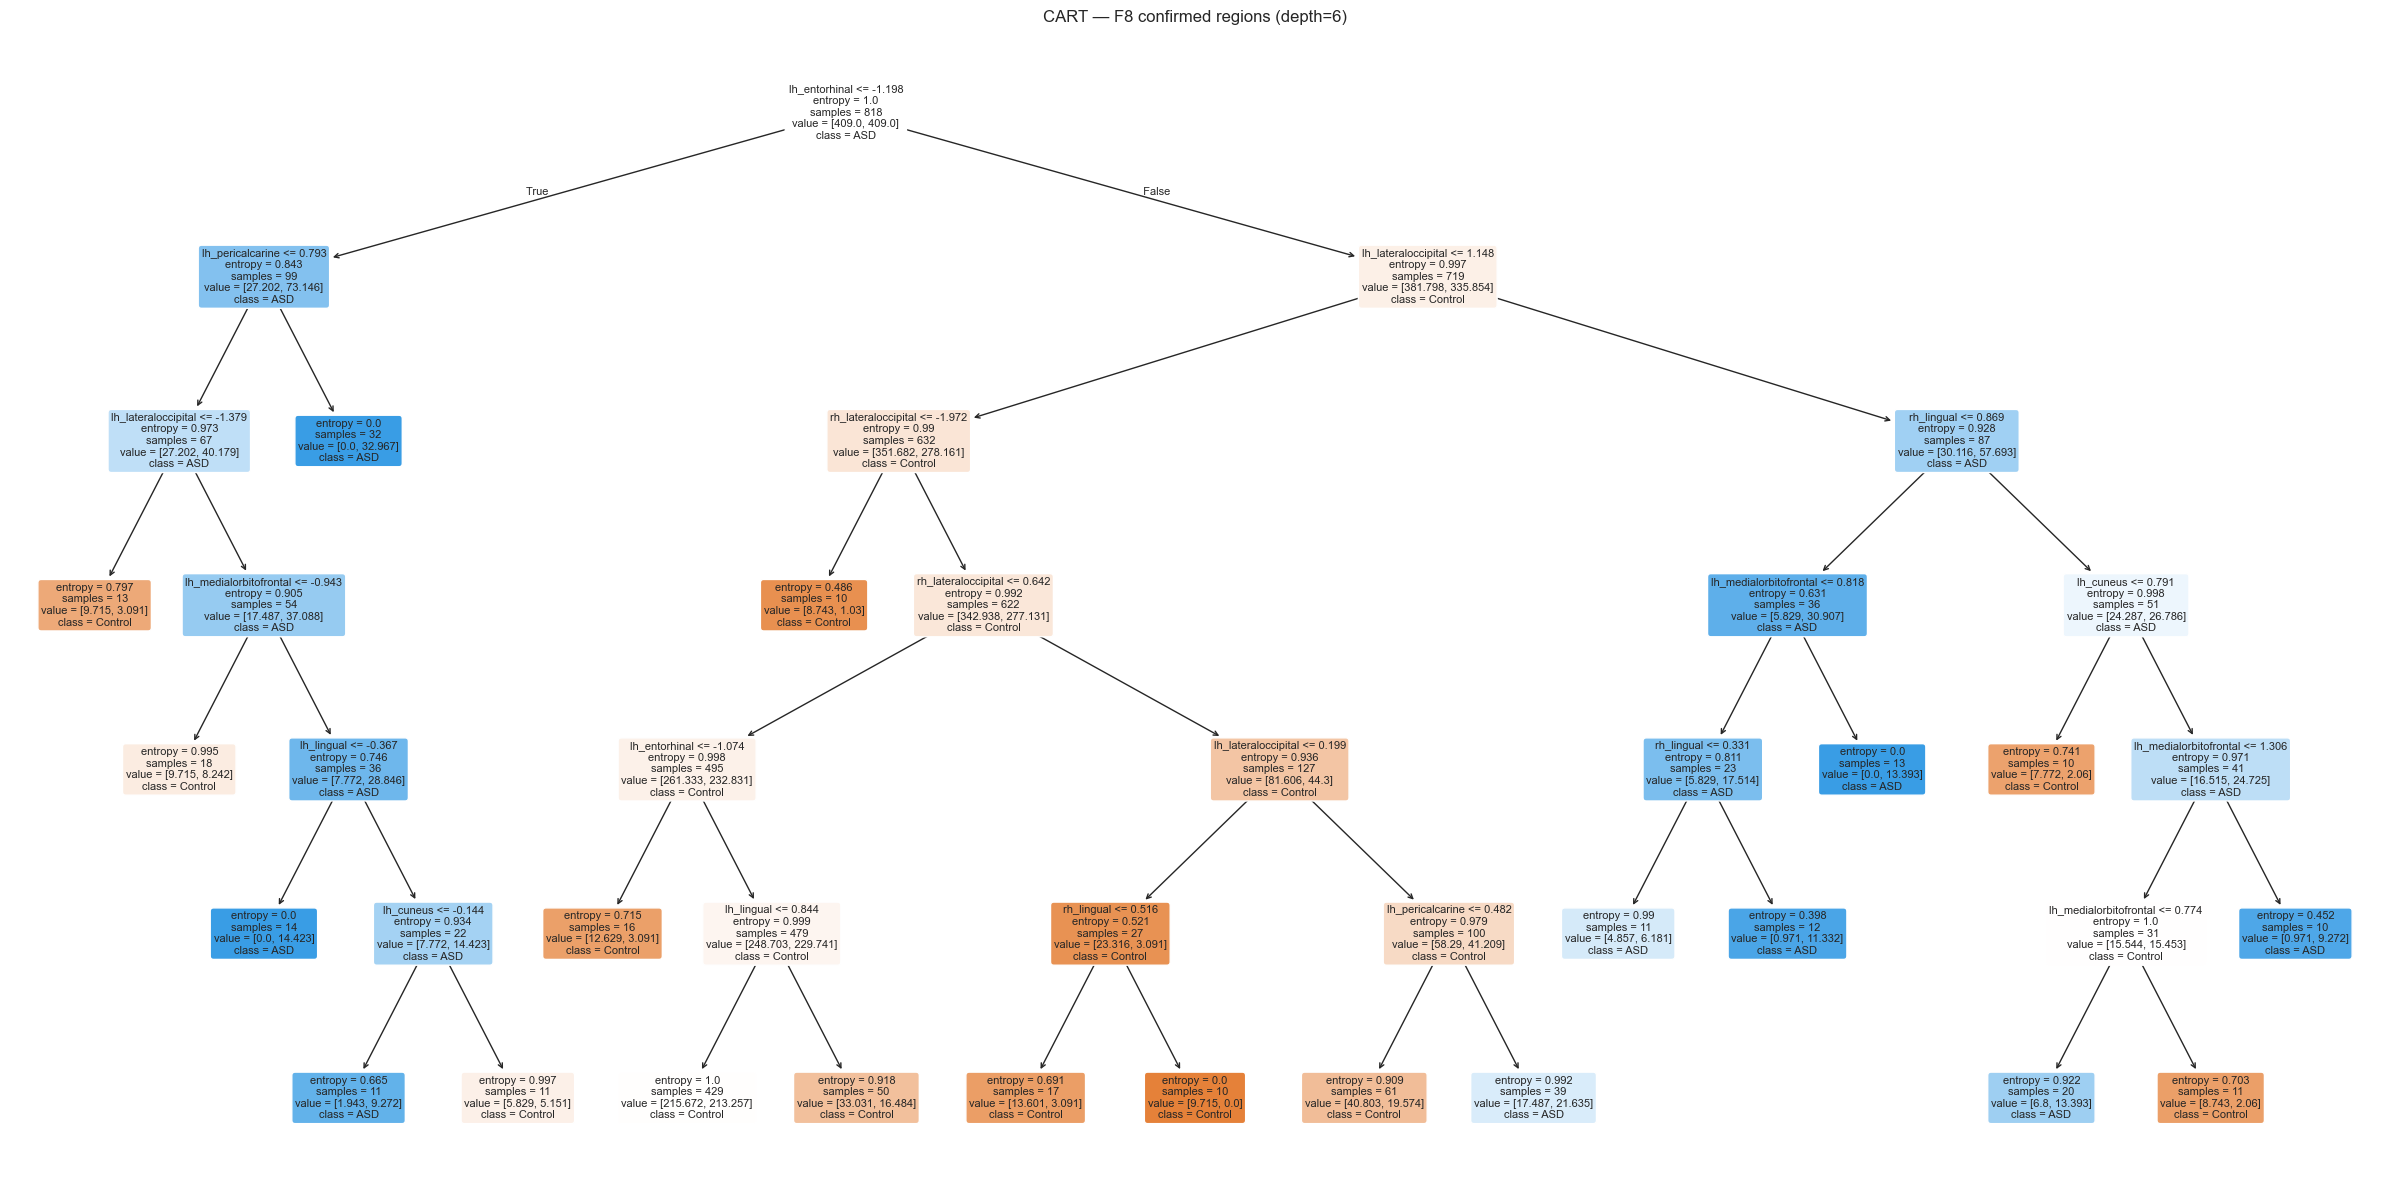

✅ CART block complete.


In [7]:
cv_results_cart, best_pipes_cart = {}, {}
grid_cart = {
    'clf__max_depth'       : [3, 4, 5, 6, 8, None],
    'clf__min_samples_leaf': [5, 10, 15, 20],
    'clf__criterion'       : ['gini', 'entropy'],
}

for feat, X_tr in X_train_sets.items():
    key = f'CART_{feat}'
    pipe = make_pipe(DecisionTreeClassifier(class_weight='balanced',
                                            random_state=RANDOM_STATE))
    gs = GridSearchCV(pipe, grid_cart, cv=cv, scoring='roc_auc', n_jobs=-1, refit=True)
    gs.fit(X_tr, y_train)
    cv_res = cross_validate(gs.best_estimator_, X_tr, y_train, cv=cv, scoring=SCORING)
    cv_results_cart[key] = cv_res
    best_pipes_cart[key] = gs.best_estimator_
    print(f'CART — {feat}: best={gs.best_params_}')
    print(f'        AUC {cv_res["test_roc_auc"].mean():.3f}±{cv_res["test_roc_auc"].std():.3f} | '
          f'Acc {cv_res["test_accuracy"].mean():.3f} | '
          f'Sens {cv_res["test_sensitivity"].mean():.3f}\n')

# Visualise best F8 tree
if 'CART_F8_confirmed' in best_pipes_cart and len(CONFIRMED_8) > 0:
    tree_clf = best_pipes_cart['CART_F8_confirmed'].named_steps['clf']
    depth = tree_clf.get_depth()
    fig, ax = plt.subplots(figsize=(max(14, depth*4), max(6, depth*2)))
    plot_tree(tree_clf, feature_names=CONFIRMED_8, class_names=CLASS_NAMES,
              filled=True, rounded=True, fontsize=8, ax=ax)
    ax.set_title(f'CART — F8 confirmed regions (depth={depth})')
    plt.tight_layout(); plt.savefig('cart_tree_F8.png', dpi=130, bbox_inches='tight'); plt.show()
print('✅ CART block complete.')

---
## Block 7 — k-Nearest Neighbours

Distance-based, so scaling (in the pipeline) is essential. We tune `k`, distance metric and
weighting, and plot the k-selection curve on the full F68 set.

KNN — F8_confirmed: best={'clf__metric': 'euclidean', 'clf__n_neighbors': 3, 'clf__weights': 'distance'}
       AUC 0.552±0.042 | Acc 0.540 | Sens 0.484

KNN — F68_all: best={'clf__metric': 'manhattan', 'clf__n_neighbors': 11, 'clf__weights': 'uniform'}
       AUC 0.512±0.029 | Acc 0.513 | Sens 0.259



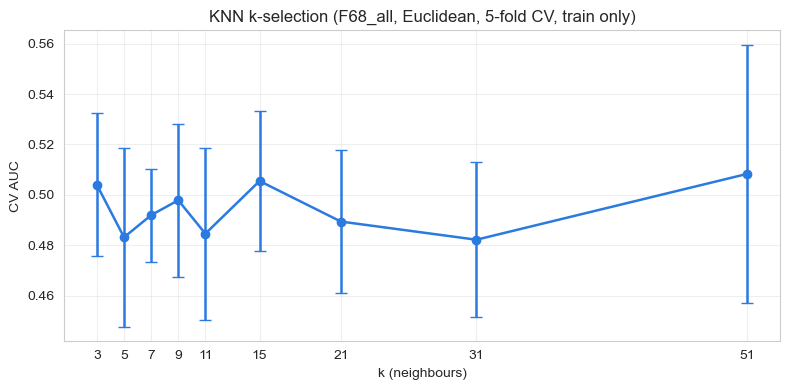

✅ KNN block complete.


In [8]:
cv_results_knn, best_pipes_knn = {}, {}
grid_knn = {
    'clf__n_neighbors': [3, 5, 7, 9, 11, 15, 21, 31],
    'clf__metric'     : ['euclidean', 'manhattan'],
    'clf__weights'    : ['uniform', 'distance'],
}

for feat, X_tr in X_train_sets.items():
    key = f'KNN_{feat}'
    gs = GridSearchCV(make_pipe(KNeighborsClassifier()), grid_knn,
                      cv=cv, scoring='roc_auc', n_jobs=-1, refit=True)
    gs.fit(X_tr, y_train)
    cv_res = cross_validate(gs.best_estimator_, X_tr, y_train, cv=cv, scoring=SCORING)
    cv_results_knn[key] = cv_res
    best_pipes_knn[key] = gs.best_estimator_
    print(f'KNN — {feat}: best={gs.best_params_}')
    print(f'       AUC {cv_res["test_roc_auc"].mean():.3f}±{cv_res["test_roc_auc"].std():.3f} | '
          f'Acc {cv_res["test_accuracy"].mean():.3f} | '
          f'Sens {cv_res["test_sensitivity"].mean():.3f}\n')

# k-selection curve on F68
feat = 'F68_all'; X_tr = X_train_sets[feat]
k_vals = [3, 5, 7, 9, 11, 15, 21, 31, 51]
means, stds = [], []
for k in k_vals:
    res = cross_validate(make_pipe(KNeighborsClassifier(n_neighbors=k, metric='euclidean')),
                         X_tr, y_train, cv=cv, scoring='roc_auc')
    means.append(res['test_score'].mean()); stds.append(res['test_score'].std())
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(k_vals, means, yerr=stds, fmt='o-', color='#2A7AE0', capsize=4, lw=1.8)
ax.set_xlabel('k (neighbours)'); ax.set_ylabel('CV AUC')
ax.set_title(f'KNN k-selection ({feat}, Euclidean, {N_SPLITS}-fold CV, train only)')
ax.set_xticks(k_vals); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig('knn_k_selection.png', dpi=120, bbox_inches='tight'); plt.show()
print('✅ KNN block complete.')

---
## Block 8 — Gaussian Naïve Bayes

Assumes conditional feature independence — a strong assumption given correlated cortical
regions — so it serves as a fast probabilistic baseline. Only `var_smoothing` is tuned.

In [9]:
cv_results_nb, best_pipes_nb = {}, {}
grid_nb = {'clf__var_smoothing': np.logspace(-12, -1, 20)}

for feat, X_tr in X_train_sets.items():
    key = f'NB_{feat}'
    gs = GridSearchCV(make_pipe(GaussianNB()), grid_nb,
                      cv=cv, scoring='roc_auc', n_jobs=-1, refit=True)
    gs.fit(X_tr, y_train)
    cv_res = cross_validate(gs.best_estimator_, X_tr, y_train, cv=cv, scoring=SCORING)
    cv_results_nb[key] = cv_res
    best_pipes_nb[key] = gs.best_estimator_
    print(f'NB — {feat}: var_smoothing={gs.best_params_["clf__var_smoothing"]:.2e}')
    print(f'      AUC {cv_res["test_roc_auc"].mean():.3f}±{cv_res["test_roc_auc"].std():.3f} | '
          f'Acc {cv_res["test_accuracy"].mean():.3f} | '
          f'Sens {cv_res["test_sensitivity"].mean():.3f}\n')
print('✅ Naïve Bayes block complete.')

NB — F8_confirmed: var_smoothing=1.00e-01
      AUC 0.569±0.045 | Acc 0.550 | Sens 0.390

NB — F68_all: var_smoothing=1.00e-01
      AUC 0.562±0.019 | Acc 0.540 | Sens 0.365

✅ Naïve Bayes block complete.


---
## Block 9 — Soft-Voting Ensemble

A soft-voting ensemble averages the predicted **probabilities** of SVM-linear, SVM-RBF,
CART, KNN and NB. The component pipelines carry the hyper-parameters chosen in Blocks 5–8;
`cross_validate` clones and refits them per fold, so the CV estimate stays honest.

In [10]:
cv_results_vote, best_pipes_vote = {}, {}

for feat, X_tr in X_train_sets.items():
    estimators = []
    for prefix, store in [('SVM_linear', best_pipes_svm), ('SVM_rbf', best_pipes_svm),
                          ('CART', best_pipes_cart), ('KNN', best_pipes_knn),
                          ('NB', best_pipes_nb)]:
        k = f'{prefix}_{feat}'
        if k in store:
            estimators.append((prefix, store[k]))
    if len(estimators) < 2:
        continue
    voter = VotingClassifier(estimators=estimators, voting='soft', n_jobs=-1)
    cv_res = cross_validate(voter, X_tr, y_train, cv=cv, scoring=SCORING)
    voter.fit(X_tr, y_train)            # refit on full train for Block 10
    key = f'Vote_{feat}'
    cv_results_vote[key] = cv_res
    best_pipes_vote[key] = voter
    print(f'Soft-Voting — {feat}: components={[n for n,_ in estimators]}')
    print(f'        AUC {cv_res["test_roc_auc"].mean():.3f}±{cv_res["test_roc_auc"].std():.3f} | '
          f'Acc {cv_res["test_accuracy"].mean():.3f} | '
          f'Sens {cv_res["test_sensitivity"].mean():.3f}\n')
print('✅ Voting ensemble complete.')

Soft-Voting — F8_confirmed: components=['SVM_linear', 'SVM_rbf', 'CART', 'KNN', 'NB']
        AUC 0.585±0.040 | Acc 0.571 | Sens 0.410

Soft-Voting — F68_all: components=['SVM_linear', 'SVM_rbf', 'CART', 'KNN', 'NB']
        AUC 0.574±0.037 | Acc 0.550 | Sens 0.365

✅ Voting ensemble complete.


---
## Block 10 — Cross-validation summary (train only)

Before touching the test set, we summarise every model's CV performance. This is what we use
to *select* the headline model; the test set only *confirms* it.

In [11]:
rows = []
for store in [cv_results_svm, cv_results_cart, cv_results_knn, cv_results_nb, cv_results_vote]:
    for name, cv_res in store.items():
        rows.append(summarise_cv(name, cv_res))
cv_summary = pd.DataFrame(rows).sort_values('roc_auc_mean', ascending=False).reset_index(drop=True)
disp = cv_summary.copy()
for c in disp.columns:
    if c != 'Model': disp[c] = disp[c].round(3)
print('=== CROSS-VALIDATION SUMMARY (train set, sorted by AUC) ===')
print(disp.to_string(index=False))
cv_summary.to_csv('rq4_cv_summary.csv', index=False)
print('\nSaved → rq4_cv_summary.csv')

=== CROSS-VALIDATION SUMMARY (train set, sorted by AUC) ===
                  Model  roc_auc_mean  roc_auc_std  accuracy_mean  accuracy_std  balanced_accuracy_mean  balanced_accuracy_std  f1_mean  f1_std  sensitivity_mean  sensitivity_std
     SVM_linear_F68_all         0.601        0.024          0.582         0.030                   0.580                  0.029    0.543   0.026             0.511            0.018
        SVM_rbf_F68_all         0.596        0.017          0.566         0.015                   0.565                  0.014    0.546   0.021             0.539            0.040
      Vote_F8_confirmed         0.585        0.040          0.571         0.022                   0.566                  0.023    0.480   0.042             0.410            0.050
      CART_F8_confirmed         0.579        0.036          0.559         0.023                   0.555                  0.020    0.468   0.080             0.427            0.170
           Vote_F68_all         0.574        

---
## Block 11 — Final test-set evaluation  🔓

**The only block that touches the sealed test set.** Each pipeline (already fit on all
training data) is scored exactly once. With ASD=1 as positive:
`predict_proba[:, 1] = P(ASD)`, sensitivity = ASD recall, specificity = Control recall.

In [12]:
all_pipes = {}
for store in [best_pipes_svm, best_pipes_cart, best_pipes_knn, best_pipes_nb, best_pipes_vote]:
    all_pipes.update(store)

print('🔓 TEST SET ACCESSED'); print('=' * 70)
rows = []
for key, pipe in sorted(all_pipes.items()):
    feat = next((f for f in FEATURE_SETS if key.endswith(f)), None)
    if feat is None:
        continue
    X_te   = X_test_sets[feat]
    y_pred = pipe.predict(X_te)
    p_asd  = pipe.predict_proba(X_te)[:, 1]          # P(ASD)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])   # rows/cols: 0=Control,1=ASD
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn) if (tp + fn) else np.nan         # ASD recall
    spec = tn / (tn + fp) if (tn + fp) else np.nan         # Control recall
    f1   = 2*tp / (2*tp + fp + fn) if (2*tp + fp + fn) else np.nan

    rows.append({
        'Model': key, 'Features': feat,
        'AUC'        : round(roc_auc_score(y_test, p_asd), 3),
        'Accuracy'   : round(accuracy_score(y_test, y_pred), 3),
        'Bal_Acc'    : round(balanced_accuracy_score(y_test, y_pred), 3),
        'Sensitivity': round(sens, 3),   # ASD
        'Specificity': round(spec, 3),   # Control
        'F1_ASD'     : round(f1, 3),
    })
    print(f'{key:<24} AUC={rows[-1]["AUC"]:.3f}  Acc={rows[-1]["Accuracy"]:.3f}  '
          f'Sens={sens:.3f}  Spec={spec:.3f}')

df_results = pd.DataFrame(rows).sort_values('AUC', ascending=False).reset_index(drop=True)
print('\n=== FINAL TEST-SET COMPARISON ===')
print(df_results.to_string(index=False))
df_results.to_csv('rq4_test_results.csv', index=False)
print('\nSaved → rq4_test_results.csv')

🔓 TEST SET ACCESSED
CART_F68_all             AUC=0.552  Acc=0.527  Sens=0.430  Spec=0.619
CART_F8_confirmed        AUC=0.551  Acc=0.546  Sens=0.270  Spec=0.810
KNN_F68_all              AUC=0.522  Acc=0.527  Sens=0.240  Spec=0.800
KNN_F8_confirmed         AUC=0.534  Acc=0.532  Sens=0.420  Spec=0.638
NB_F68_all               AUC=0.514  Acc=0.532  Sens=0.340  Spec=0.714
NB_F8_confirmed          AUC=0.552  Acc=0.522  Sens=0.350  Spec=0.686
SVM_linear_F68_all       AUC=0.508  Acc=0.527  Sens=0.490  Spec=0.562
SVM_linear_F8_confirmed  AUC=0.557  Acc=0.566  Sens=0.270  Spec=0.848
SVM_rbf_F68_all          AUC=0.554  Acc=0.551  Sens=0.540  Spec=0.562
SVM_rbf_F8_confirmed     AUC=0.559  Acc=0.517  Sens=0.370  Spec=0.657
Vote_F68_all             AUC=0.549  Acc=0.556  Sens=0.350  Spec=0.752
Vote_F8_confirmed        AUC=0.560  Acc=0.541  Sens=0.360  Spec=0.714

=== FINAL TEST-SET COMPARISON ===
                  Model     Features   AUC  Accuracy  Bal_Acc  Sensitivity  Specificity  F1_ASD
      Vot

---
## Block 12 — Figures: AUC comparison, ROC curves, confusion matrix

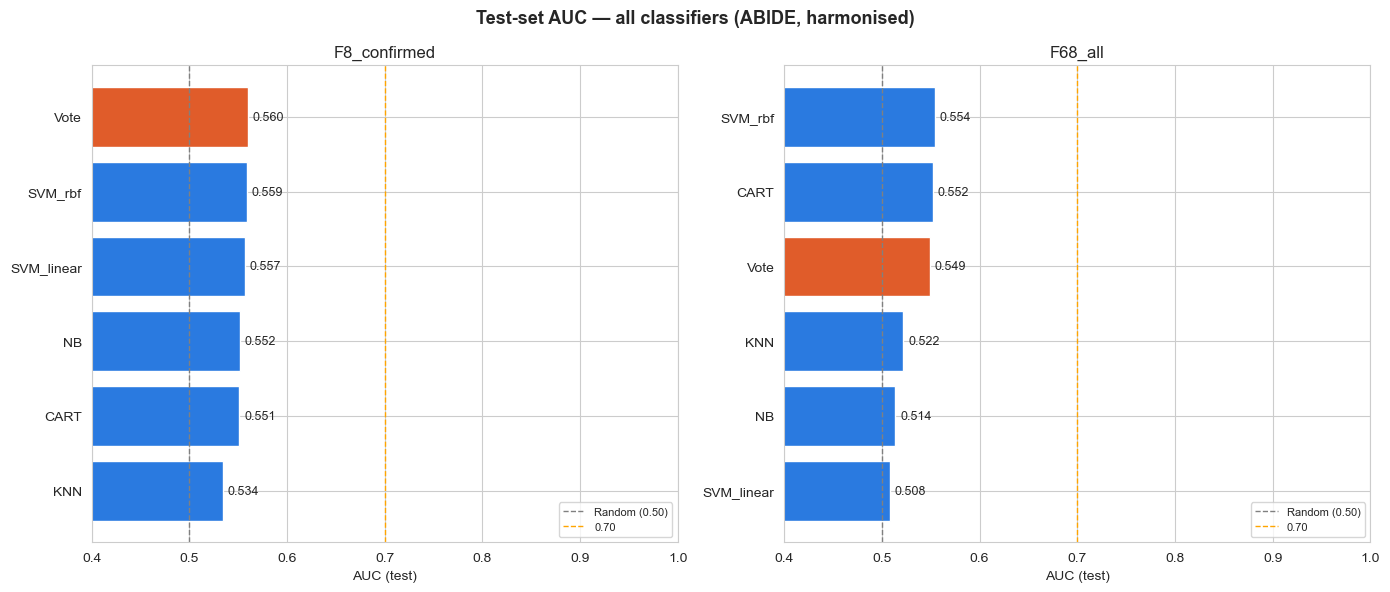

In [13]:
# Figure 1 — AUC bar chart per feature set
feats = list(FEATURE_SETS.keys())
fig, axes = plt.subplots(1, len(feats), figsize=(7*len(feats), 6), squeeze=False)
fig.suptitle('Test-set AUC — all classifiers (ABIDE, harmonised)', fontsize=13, fontweight='bold')
for ax, feat in zip(axes[0], feats):
    sub = df_results[df_results.Features == feat].sort_values('AUC')
    colors = ['#E05C2A' if 'Vote' in m else '#2A7AE0' for m in sub.Model]
    names = sub.Model.str.replace(f'_{feat}', '', regex=False)
    bars = ax.barh(names, sub.AUC, color=colors, edgecolor='white')
    ax.axvline(0.5, color='grey', ls='--', lw=1, label='Random (0.50)')
    ax.axvline(0.7, color='orange', ls='--', lw=1, label='0.70')
    ax.set_xlim(0.4, 1.0); ax.set_xlabel('AUC (test)'); ax.set_title(feat)
    for b, v in zip(bars, sub.AUC):
        ax.text(v + 0.005, b.get_y() + b.get_height()/2, f'{v:.3f}', va='center', fontsize=9)
    ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.savefig('rq4_test_auc.png', dpi=130, bbox_inches='tight'); plt.show()

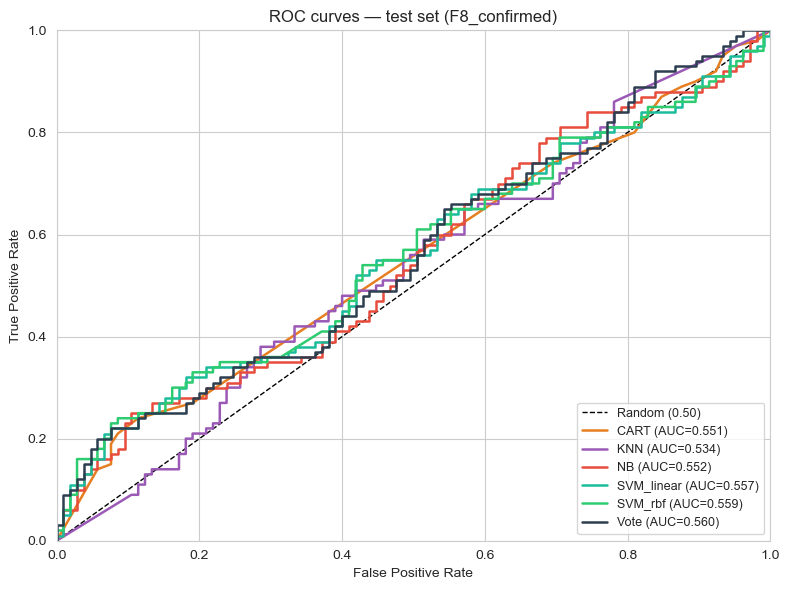

In [14]:
# Figure 2 — ROC curves (best feature set = the one holding the top model)
best_feat = df_results.iloc[0]['Features']
algo_colors = {'SVM_linear':'#1abc9c','SVM_rbf':'#2ecc71','CART':'#e67e22',
               'KNN':'#9b59b6','NB':'#e74c3c','Vote':'#2c3e50'}
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (0.50)')
for key, pipe in sorted(all_pipes.items()):
    if not key.endswith(best_feat):
        continue
    X_te = X_test_sets[best_feat]
    p_asd = pipe.predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p_asd)             # pos_label defaults to 1 = ASD
    algo = key.replace(f'_{best_feat}', '')
    color = next((v for k, v in algo_colors.items() if algo.startswith(k)), '#555')
    ax.plot(fpr, tpr, lw=1.8, color=color, label=f'{algo} (AUC={auc(fpr,tpr):.3f})')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title(f'ROC curves — test set ({best_feat})')
ax.legend(fontsize=9, loc='lower right'); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout(); plt.savefig('rq4_roc_curves.png', dpi=130, bbox_inches='tight'); plt.show()

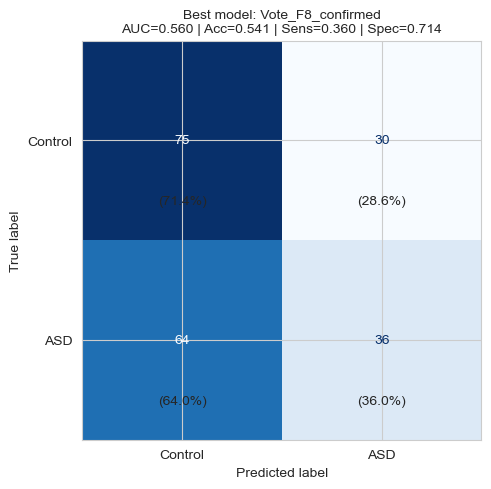

              precision    recall  f1-score   support

     Control       0.54      0.71      0.61       105
         ASD       0.55      0.36      0.43       100

    accuracy                           0.54       205
   macro avg       0.54      0.54      0.52       205
weighted avg       0.54      0.54      0.53       205



Exception ignored in: <function ResourceTracker.__del__ at 0x106e2dbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x106d15bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x104eb9bc0>
Traceback (most recent call last

In [ ]:
# Figure 3 — Confusion matrix of the best model
best = df_results.iloc[0]
best_pipe = all_pipes[best.Model]
X_te = X_test_sets[best.Features]
y_pred = best_pipe.predict(X_te)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, colorbar=False, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i + 0.32, f'({cm[i,j]/cm[i].sum()*100:.1f}%)', ha='center', fontsize=10)
ax.set_title(f'Best model: {best.Model}\n'
             f'AUC={best.AUC:.3f} | Acc={best.Accuracy:.3f} | '
             f'Sens={best.Sensitivity:.3f} | Spec={best.Specificity:.3f}', fontsize=10)
plt.tight_layout(); plt.savefig('rq4_confusion_best.png', dpi=130, bbox_inches='tight'); plt.show()
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES))

---
## Block 13 — Interpretation

Fill in once the cells have run on the real data:

- **Headline model:** the top row of the Block 11 table (selected by CV in Block 10,
  confirmed on the sealed test set).
- **CV vs. test gap:** compare `rq4_cv_summary.csv` with `rq4_test_results.csv`. A large drop
  from CV-AUC to test-AUC signals over-fitting; similar values indicate stable generalisation.
- **F8 vs. F68:** if F8 matches or beats F68, the RQ1-confirmed regions carry the classification
  signal and the extra 60 regions mostly add noise.
- **Sensitivity vs. specificity:** with ASD as the positive class, sensitivity is the share of
  ASD subjects correctly identified — usually the clinically important number to report.

**Reproducibility:** all randomness is fixed via `RANDOM_STATE`; preprocessing is inside the
pipeline; the test set is opened only in Block 11.